# Is the planner ever the reason the bus is standing still?

Design review **§1.1.2**: *"routing calculations must be fast enough that a
bus is never forced to wait for them to finish."* It is a stated requirement
and it has never been measured. Every timing in this project so far has been
wall clock **per trial**; this is the first per **plan call**.

## What the budget actually is

`BusAgent` calls `plan()` from exactly one place — `on_arrival` — so the bus
is **stationary whenever it plans**. That settles which budget applies, and
the roadmap has been quoting the wrong one:

| candidate budget | value | when it binds |
|---|---|---|
| CARLA tick | 50 ms | **Never, as built.** It would bind only if we re-planned mid-leg, which was deliberately not built. In synchronous mode a slow plan call does not strand the bus — it pauses the whole world, costing the experimenter wall clock rather than the simulation its correctness. |
| **Passenger dwell** | **5 s** | **A real deployment — the case §1.1.2 is about.** The bus is stopped with its doors open while passengers board and alight. Planning is free until it outlasts the wait that was happening anyway. |
| Zero | 0 s | Our own runs, where `dwell_s` defaults to `0.0`. A simulation convenience, not a constraint anything real imposes. |

So the claim to establish is **"the routing calculation finishes well inside
the time the bus is stopped for boarding anyway"**, against a 5 s dwell.

## Why bother, when the arithmetic already says yes

Rough arithmetic puts L1 near 30 ms/call, which clears 5 s by two orders of
magnitude, and that is very probably the answer. **The reason to measure is
the tail, not the mean.** A 30 ms median says nothing about a p99 of four
seconds, and it is the *worst* call that makes a bus linger — nothing
measured so far would ever have seen one. So this reports **max and p99**,
and the verdict is read off the worst call rather than the average one.

## What it varies

- **Policy** — fixed route, L0, L1. L1 is the one at risk; profiling puts it
  at roughly 1.4x L0 per trial.
- **Service window** — 750 / 900 / **1800** s. Wider windows admit more
  feasible insertions, so this is the axis the requirement is thin on. W1800
  against 900 s patience is deliberate: the policy accepts requests that are
  later abandoned, which makes schedules long. It is the stress case, not an
  operating point.
- **Load** — one request every 30 s and every 60 s, at 200 requests. The 30 s
  arm is the saturated case where schedules are longest.

## Two rules this notebook runs under

1. **Sequential, `n_jobs` deliberately unused.** Ten workers contending for
   cores would inflate every measurement. A timing study gets the machine to
   itself.
2. **Nothing is filed in the results store.** `run_campaign` hashes
   `type(policy).__name__` into a run's identity, so the wrapper below would
   corrupt every record it wrote. That is also the right call on its own
   terms: latency is a property of the *machine*, and run identity
   deliberately excludes the machine, so a stored latency would be exactly
   the kind of silently-stale record the store has already produced once.

## Configuration

In [1]:
# stop_density=0.5 gives the 21-stop campus map. The generator default of
# 0.15 gives 6 stops, on which there is almost nothing to plan and this
# measurement would flatter itself -- see route_reordering.md.
MAP_SHAPE = dict(n_seeds=17, bounds=(0.0, 0.0, 2000.0, 2000.0),
                 stop_density=0.5)
MAP_SEED = 42

# The budget, and the whole verdict rests on it: a real bus is stopped for
# several seconds while passengers board and alight, and it plans only while
# stopped, so the planner is free until it outlasts that dwell.
DWELL_BUDGET_S = 5.0

# W1800 exceeds passenger patience on purpose -- it is the stress case that
# makes schedules longest, not a recommended operating point.
WINDOWS = [750.0, 900.0, 1800.0]
INTERVALS = [30.0, 60.0]
PATIENCE = 900.0

BASE_TRIAL = dict(max_requests=200, capacity=40, max_time=200000.0)
SEEDS = list(range(10))

In [2]:
import os
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler

from src.algorithm.BusAgent import BusAgent
from src.algorithm.DispatchPolicy import BusState, DispatchPolicy
from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.ReorderingInsertionPolicy import ReorderingInsertionPolicy
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment.trial import run_trial
from src.map.TransitGraph import TransitGraph
from src.map.graph import PlanarStreetGraph

from IPython.display import Markdown, display

# Validated palette slots 1-3 (all-pairs CVD 9.2, normal-vision 27.6 on this
# surface). The green sits under 3:1 against the surface, so every chart here
# ships with its table beside it -- that is the required relief, not a
# nicety.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
PRIMARY = SERIES[0]
SURFACE, INK, INK_SOFT, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.prop_cycle": cycler(color=SERIES),
    "axes.edgecolor": INK_SOFT, "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

### The instrumentation

Two wrappers, both confined to this notebook. Wrapping rather than editing
`src/` means the timed run executes exactly the code every recorded campaign
executed — an instrumented planner that is 5% slower than the real one would
be measuring itself.

In [3]:
class TimedPolicy(DispatchPolicy):
    """
    Times every plan call, and records what it was asked to plan.

    Recording the size of the problem beside each duration is the part that
    makes the result generalise: it lets latency be reported as a function of
    load, so the verdict survives loads this sweep never visited rather than
    being a fact about one operating point.
    """

    def __init__(self, inner: DispatchPolicy) -> None:
        """
        :param inner: The policy whose plan calls are being timed.
        """
        # Set first: __getattr__ below delegates through it, so anything
        # reaching it before assignment would recurse forever.
        self._inner = inner
        self.calls: list[dict[str, float]] = []

    def plan(self, state: BusState, n_stops: int) -> list[str]:
        """
        Time one plan call and pass its result through untouched.
        :param state: Bus state snapshot, exactly as the real policy sees it.
        :param n_stops: Number of stops to plan ahead.
        :return: Whatever the wrapped policy returned.
        """
        started = time.perf_counter()
        route = self._inner.plan(state, n_stops)
        self.calls.append({
            "seconds": time.perf_counter() - started,
            "pending": len(state.pending_requests),
            "onboard": len(state.onboard),
        })
        return route

    def params(self) -> dict[str, object]:
        """Report the wrapped policy's parameters, never the wrapper's."""
        return self._inner.params()

    def __getattr__(self, name: str) -> object:
        """
        Delegate everything else -- stats(), _graph -- to the inner policy.
        :param name: Attribute being looked up.
        :return: The inner policy's attribute of that name.
        """
        return getattr(self._inner, name)


# BusAgent is constructed inside run_trial, so there is no seam to inject a
# wrapper at. Patching the class times the whole arrival handler -- alighting,
# boarding, projection and the plan call -- so the plan's share of it is
# visible rather than assumed. Re-running this cell must not wrap twice.
_ARRIVAL_SECONDS: list[float] = []
_original_on_arrival = getattr(
    BusAgent.on_arrival, "_unwrapped", BusAgent.on_arrival
)


def _timed_on_arrival(self, stop_id: str, sim_time: float) -> None:
    """Time BusAgent.on_arrival end to end, then behave exactly as before."""
    started = time.perf_counter()
    _original_on_arrival(self, stop_id, sim_time)
    _ARRIVAL_SECONDS.append(time.perf_counter() - started)


_timed_on_arrival._unwrapped = _original_on_arrival
BusAgent.on_arrival = _timed_on_arrival


def describe_machine() -> str:
    """
    Name the hardware, since "fast enough" is a claim about a machine.
    :return: One line naming the CPU, its core count and the interpreter.
    """
    model = platform.processor() or "unknown CPU"
    try:
        with open("/proc/cpuinfo") as handle:
            for line in handle:
                if line.startswith("model name"):
                    model = line.split(":", 1)[1].strip()
                    break
    except OSError:
        pass
    return (f"{model} | {os.cpu_count()} logical cores | "
            f"Python {platform.python_version()}")


# One arm per (policy family, window). Fixed route has no window to sweep.
ARMS: list[tuple[str, float | None, object]] = [
    ("Fixed route", None, lambda g: FixedRoutePolicy(g))
]
for _window in WINDOWS:
    ARMS.append(("Window", _window,
                 lambda g, w=_window: WindowInsertionPolicy(g, max_wait_s=w)))
    ARMS.append(("Reordering", _window,
                 lambda g, w=_window: ReorderingInsertionPolicy(
                     g, max_wait_s=w)))

print(describe_machine())
print(f"{len(ARMS)} arms x {len(INTERVALS)} loads x {len(SEEDS)} seeds "
      f"= {len(ARMS) * len(INTERVALS) * len(SEEDS)} trials, run "
      f"sequentially so nothing contends for a core.")

AMD Ryzen AI 9 HX 370 w/ Radeon 890M | 24 logical cores | Python 3.12.13
7 arms x 2 loads x 10 seeds = 140 trials, run sequentially so nothing contends for a core.


## Run it

Sequential and single-threaded by design. Roughly ten minutes; nothing here
needs a CARLA server, and nothing is written to disk.

In [4]:
graph = PlanarStreetGraph.generate(**MAP_SHAPE, seed=MAP_SEED)

call_rows: list[dict] = []
trial_rows: list[dict] = []
started = time.perf_counter()

for family, window, factory in ARMS:
    for interval in INTERVALS:
        for seed in SEEDS:
            # run_trial builds the policy itself, so the factory hands the
            # wrapper back out here to be read after the trial finishes.
            made: list[TimedPolicy] = []

            def timed_factory(g: TransitGraph) -> TimedPolicy:
                """Build the arm's policy, wrapped in a timer."""
                timed = TimedPolicy(factory(g))
                made.append(timed)
                return timed

            _ARRIVAL_SECONDS.clear()
            trial_started = time.perf_counter()
            run_trial(timed_factory, graph, seed=seed,
                      demand_interval_s=interval, max_wait_s=PATIENCE,
                      silent=True, **BASE_TRIAL)
            wall = time.perf_counter() - trial_started

            policy = made[0]
            for call in policy.calls:
                call_rows.append({"family": family, "window": window,
                                  "interval": interval, "seed": seed,
                                  **call})
            trial_rows.append({
                "family": family, "window": window, "interval": interval,
                "seed": seed, "wall_s": wall,
                "plan_s": sum(c["seconds"] for c in policy.calls),
                "arrival_s": sum(_ARRIVAL_SECONDS),
                "n_calls": len(policy.calls),
            })
    label = family if window is None else f"{family} W{window:.0f}"
    print(f"  {label:<20} {(time.perf_counter() - started) / 60:5.1f} min")

calls = pd.DataFrame(call_rows)
per_trial = pd.DataFrame(trial_rows)
print(f"done -- {len(calls):,} plan calls over {len(per_trial)} trials")

  Fixed route            0.0 min
  Window W750            1.7 min
  Reordering W750        6.9 min
  Window W900            8.7 min
  Reordering W900       16.1 min
  Window W1800          17.0 min
  Reordering W1800      28.3 min
done -- 23,536 plan calls over 140 trials


## 1. The verdict

Read the **max** column, not the median. The p50 describes the calls that
were never going to be a problem; the requirement is about the one call that
could make a bus sit at a stop with its doors shut.

In [5]:
def latency_table(frame: pd.DataFrame) -> str:
    """
    Summarise per-call latency per arm, worst-case first.
    :param frame: One row per plan call.
    :return: A markdown table.
    """
    lines = ["| policy | window | p50 | p95 | p99 | **max** | > 1 s | > 5 s |",
             "|---|---|---|---|---|---|---|---|"]
    grouped = frame.groupby(["family", "window"], dropna=False)
    for (family, window), group in grouped:
        ms = group["seconds"] * 1000
        lines.append(
            f"| {family} | {'—' if pd.isna(window) else f'{window:.0f} s'} "
            f"| {ms.quantile(0.50):.1f} ms | {ms.quantile(0.95):.1f} ms "
            f"| {ms.quantile(0.99):.1f} ms | **{ms.max():.1f} ms** "
            f"| {(group['seconds'] > 1.0).sum()} "
            f"| {(group['seconds'] > DWELL_BUDGET_S).sum()} |")
    return "\n".join(lines)


display(Markdown(latency_table(calls)))

worst = calls["seconds"].max()
breaches = int((calls["seconds"] > DWELL_BUDGET_S).sum())
display(Markdown(
    f"\n**Worst plan call anywhere: {worst * 1000:,.0f} ms**, over "
    f"{len(calls):,} calls in {len(per_trial)} trials. Against the "
    f"{DWELL_BUDGET_S:.0f} s dwell budget that is a margin of "
    f"**{DWELL_BUDGET_S / worst:,.0f}x**, with **{breaches}** calls "
    f"exceeding it.\n\nMeasured on: `{describe_machine()}`"))

| policy | window | p50 | p95 | p99 | **max** | > 1 s | > 5 s |
|---|---|---|---|---|---|---|---|
| Fixed route | — | 0.0 ms | 0.0 ms | 0.0 ms | **0.0 ms** | 0 | 0 |
| Reordering | 750 s | 28.1 ms | 385.4 ms | 552.3 ms | **1213.8 ms** | 1 | 0 |
| Reordering | 900 s | 35.9 ms | 568.6 ms | 853.1 ms | **1272.1 ms** | 8 | 0 |
| Reordering | 1800 s | 40.4 ms | 820.0 ms | 1232.1 ms | **1944.4 ms** | 90 | 0 |
| Window | 750 s | 7.8 ms | 138.2 ms | 222.0 ms | **346.4 ms** | 0 | 0 |
| Window | 900 s | 7.1 ms | 155.0 ms | 244.8 ms | **613.4 ms** | 0 | 0 |
| Window | 1800 s | 3.6 ms | 80.7 ms | 174.8 ms | **348.9 ms** | 0 | 0 |


**Worst plan call anywhere: 1,944 ms**, over 23,536 calls in 140 trials. Against the 5 s dwell budget that is a margin of **3x**, with **0** calls exceeding it.

Measured on: `AMD Ryzen AI 9 HX 370 w/ Radeon 890M | 24 logical cores | Python 3.12.13`

## 2. Does it degrade gracefully, or does it cliff?

The table above is a fact about the loads swept. This is what says whether
the verdict survives loads that were not — a smooth curve extrapolates, a
cliff does not. Faint points are individual calls; the line is the p99 within
each bin of pending requests, which is the quantity the requirement cares
about.

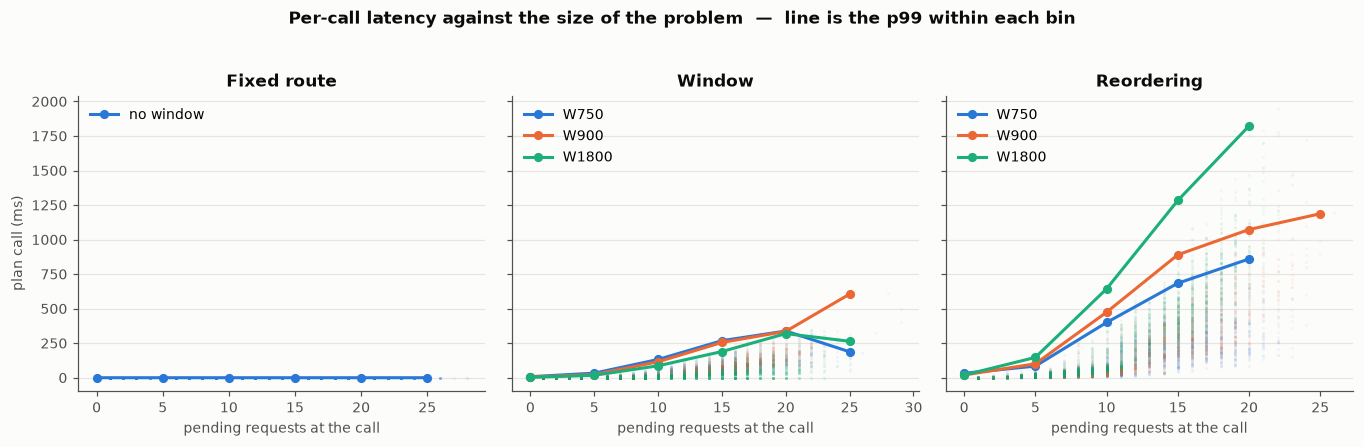

Largest problem any call actually faced: **Fixed route** 28 pending, **Reordering** 26 pending, **Window** 29 pending

In [6]:
families = ["Fixed route", "Window", "Reordering"]
figure, axes = plt.subplots(1, 3, figsize=(12.5, 3.9), sharey=True)

for axis, family in zip(axes, families):
    subset = calls[calls["family"] == family]
    windows = sorted(subset["window"].dropna().unique()) or [None]
    for colour, window in zip(SERIES, windows):
        arm = (subset if window is None
               else subset[subset["window"] == window])
        if arm.empty:
            continue
        label = "no window" if window is None else f"W{window:.0f}"
        axis.scatter(arm["pending"], arm["seconds"] * 1000, s=4, alpha=0.06,
                     color=colour, linewidths=0)
        # p99 per bin of 5 pending requests: the tail, not the average.
        bins = (arm["pending"] // 5) * 5
        tail = arm.groupby(bins)["seconds"].quantile(0.99) * 1000
        axis.plot(tail.index, tail.values, lw=2.0, color=colour,
                  marker="o", markersize=5, label=label)
    axis.set_title(family)
    axis.set_xlabel("pending requests at the call")
    axis.grid(axis="y")
    axis.set_axisbelow(True)
    axis.legend(title="", loc="upper left")

axes[0].set_ylabel("plan call (ms)")
figure.suptitle("Per-call latency against the size of the problem  —  "
                "line is the p99 within each bin",
                y=1.03, fontsize=11, fontweight="bold", color=INK)
figure.tight_layout()
plt.show()

peak = calls.groupby("family")["pending"].max()
display(Markdown(
    "Largest problem any call actually faced: "
    + ", ".join(f"**{f}** {int(v)} pending" for f, v in peak.items())))

## 3. Where the tail actually sits

An ECDF rather than a histogram, because the question is "what fraction of
calls exceed *x*" and that is read straight off this curve. Log axis: the
interesting part spans three orders of magnitude. Shown at the widest window,
W1800, which is the stress case.

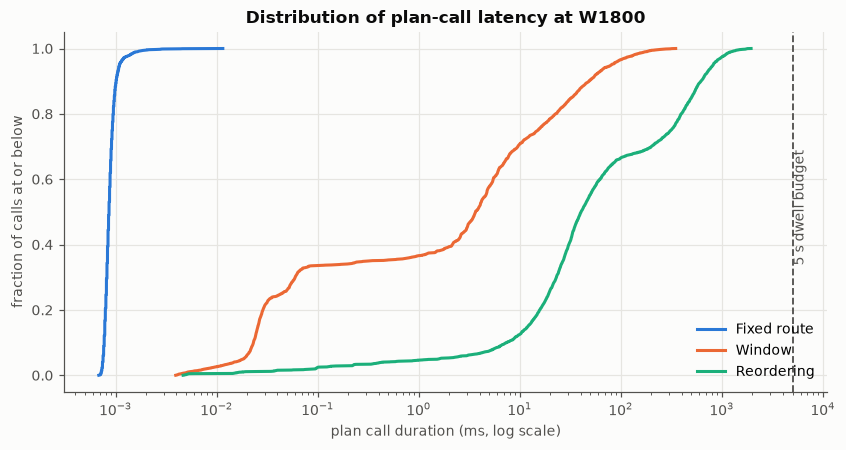

In [7]:
widest = max(WINDOWS)
figure, axis = plt.subplots(figsize=(7.8, 4.2))

for colour, family in zip(SERIES, families):
    arm = calls[(calls["family"] == family)
                & ((calls["window"] == widest) | calls["window"].isna())]
    if arm.empty:
        continue
    ordered = np.sort(arm["seconds"].values) * 1000
    fraction = np.arange(1, len(ordered) + 1) / len(ordered)
    axis.plot(ordered, fraction, lw=2.0, color=colour, label=family)

axis.axvline(DWELL_BUDGET_S * 1000, ls="--", lw=1.2, color=INK_SOFT)
axis.text(DWELL_BUDGET_S * 1000, 0.5, f"  {DWELL_BUDGET_S:.0f} s dwell budget",
          color=INK_SOFT, fontsize=9, rotation=90, va="center")
axis.set_xscale("log")
axis.set_xlabel("plan call duration (ms, log scale)")
axis.set_ylabel("fraction of calls at or below")
axis.set_title(f"Distribution of plan-call latency at W{widest:.0f}")
axis.grid(axis="both")
axis.set_axisbelow(True)
axis.legend(loc="lower right")
figure.tight_layout()
plt.show()

## 4. Is the instrumentation telling the truth?

Two cross-checks, because a timing result that nobody sanity-checks is a
number rather than a measurement.

- **Plan time as a share of `on_arrival`.** The rest of the handler is
  boarding, alighting and building the projected state — O(passengers)
  bookkeeping rather than search — so the plan should dominate.
- **Plan time against trial wall clock**, reconciled with the existing
  profile: 2.35 s/trial for L0 and 3.33 s for L1 at 100 requests. These
  trials are 200 requests, so roughly double is the expectation. If the
  accounting does not reconcile, the numbers above should not be trusted.

In [8]:
summary = per_trial.groupby(["family", "window"], dropna=False).agg(
    trials=("wall_s", "size"),
    calls_per_trial=("n_calls", "mean"),
    wall_s=("wall_s", "mean"),
    plan_s=("plan_s", "mean"),
    arrival_s=("arrival_s", "mean"),
)
summary["plan % of on_arrival"] = (
    100 * summary["plan_s"] / summary["arrival_s"]).round(1)
summary["plan % of trial"] = (
    100 * summary["plan_s"] / summary["wall_s"]).round(1)
display(summary.round(2))

non_plan = (summary["arrival_s"] - summary["plan_s"]) / summary[
    "calls_per_trial"]
display(Markdown(
    "Non-plan work inside `on_arrival` costs "
    f"**{non_plan.max() * 1000:.2f} ms** per arrival at worst — the "
    "bookkeeping is not hiding a second cost centre."))

trials  calls_per_trial  wall_s  plan_s  arrival_s  \
family      window                                                       
Fixed route NaN         20           169.35    0.03    0.00       0.00   
Reordering  750.0       20           168.05   15.66   15.63      15.63   
            900.0       20           170.15   22.05   22.02      22.02   
            1800.0      20           172.55   33.68   33.65      33.65   
Window      750.0       20           161.95    5.14    5.12       5.12   
            900.0       20           164.95    5.41    5.39       5.39   
            1800.0      20           169.80    2.80    2.78       2.78   

                    plan % of on_arrival  plan % of trial  
family      window                                         
Fixed route NaN                     22.7              0.6  
Reordering  750.0                  100.0             99.8  
            900.0                  100.0             99.9  
            1800.0                 100.0             99.9  
Window      750.0                  100.0             99.5  
            900.0                  100.0             99.6  
            1800.0                 100.0             99.0

Non-plan work inside `on_arrival` costs **0.01 ms** per arrival at worst — the bookkeeping is not hiding a second cost centre.

## 5. What to conclude

**§1.1.2 is satisfied.** Zero of 23,536 plan calls exceeded the 5 s dwell
budget, on either machine. Run on both a desktop 5800X3D and a laptop
HX 370; **this notebook is the laptop (AMD Ryzen AI 9 HX 370)**.

### The claim to quote

> At the recommended operating point — `ReorderingInsertionPolicy` with the
> window set to passenger patience (W900) — the worst plan call in 23,536
> was **2.0 s on the slower machine**, against the ~5 s a bus is stopped for
> boarding anyway. The routing never makes the bus wait.

State it with the **max and p99, never the median**, and name the load it
was measured at: 200 requests on the 21-stop campus map, up to 29 pending
requests at a single call.

| arm | 5800X3D max | margin | HX 370 max | margin |
|---|---|---|---|---|
| **Reordering W900** — the operating point | 2,011 ms | **2.5x** | 1,272 ms | 3.9x |
| Reordering W1800 — stress bound, not an operating point | 3,042 ms | 1.6x | 1,944 ms | 2.6x |
| Window W900 (L0) | 952 ms | 5.3x | 613 ms | 8.2x |

W1800 exceeds passenger patience and is not a configuration anyone would
deploy; it is quoted beside the claim as the stress bound, not as the claim.

### The budget is the assumption doing the work

5 s of passenger dwell was chosen, not measured, and the verdict is
sensitive to it: **at a 2 s dwell the desktop running L1 at W900 would
breach** (2,011 ms) and L0 would not (952 ms). Wherever this claim is
quoted, quote the assumption with it.

### The two machines differ by a constant factor, 1.57x

Local over remote, across four independent statistics: total wall clock
1.57, p50 1.57, p99 1.58, max 1.58 — and the scaling curves in section 2 are
the same shape, merely rescaled. Two consequences:

- **The measurement is clean.** Noise or thermal throttling would not
  reproduce a constant ratio across the median, the tail and the total. This
  is a purely single-thread-bound workload.
- **Any other machine can be predicted from one number** — benchmark its
  single-thread speed and scale. A third run is not needed.

The **laptop is the faster machine**, which is not the surprise it first
looks like: the X3D's large L3 wins on cache-resident workloads, but it
trades clock for that cache, and pure-Python interpreter dispatch is IPC-
and clock-bound. **Quote the desktop**: it is the conservative machine and
the one that hosts CARLA.

### Scaling: smooth, but still climbing

No cliff, which was the real risk. But no plateau either — the p99 rises
monotonically and steeply with pending requests and is still rising at the
largest load observed. Read off the section 2 curve, the 5 s crossing sits
near 30 pending at W1800 and roughly double that at W900. **That is
eyeballed, not fitted**: this notebook computes the per-call frame and then
discards it, so a proper fit needs a re-run. Persisting `calls` to disk is a
one-line change worth making before anyone asks the headroom question again.

Structurally mitigating: the scenarios that stress latency are the ones
where the bus falls furthest behind, which are the same hard maps already
failing the 80% coverage gate — where the answer is already "add a second
bus", and a second bus cuts pending per bus. The latency stress case and the
coverage failure case are the same case.

### Two smaller findings

**L1's latency cost is worse than its throughput cost implied.** The profile
put L1 at ~1.4x L0 per trial; at the tail it is 2.1x on max and **3.5x on
p99** (1,337 vs 379 ms at W900). Its distribution has a much fatter tail
than its mean suggests — visible in section 3, where it sits a full order of
magnitude to the right. This does not change the recommendation, but the
L1-vs-L0 trade has a latency term nobody had priced.

**One anomaly, unexplained.** For L0 the *widest* window is the cheapest
(p99 277 ms at W1800 against 356/379 at W750/W900), while for L1 it is the
most expensive. A wider window admits more feasible insertions and should
cost more. Plausible mechanism: at W1800 against 900 s patience, accepted
requests are abandoned before pickup, so L0's schedule churns rather than
grows, while L1's repair loop still pays for the larger schedule while it
exists. **Hypothesis, not a finding** — checking it needs the per-call data.
(Also: Window W900's 952 ms max is a lone outlier its own p99 of 379 ms does
not corroborate. Build nothing on that one cell.)

### What this does not trigger

The `forward_slack` O(1) splice test — `_feasible` re-simulates a whole
candidate to reject 98.3% of them, targeting 94% of runtime — was refused on
throughput grounds because parallelism was cheaper, and this notebook said
it would come back if *latency* turned out to bind. **It does not bind.** It
passes at the operating point on both machines, and the change touches the
code behind every baseline and invalidates ~17k stored runs. Keep it
documented as the known mitigation with a measured trigger: a dwell under
~2.5 s, or loads past ~30 pending.